# Поиск аномалий в показателях банков: LOF и Isolation Forest

## Самостоятельная работа по файлу `banks.txt`

**Данные:** `data/banks.txt` — показатели российских банков (кодировка `cp1251`, 371 банк, 5 числовых показателей):

| Столбец | Смысл |
|---|---|
| `Bank` | название банка (идентификатор, в модель не входит) |
| `Assents` | активы |
| `OwnCapital` | собственный капитал |
| `IndFunds` | средства физических лиц |
| `NBSLoans` | кредиты небанковскому сектору |
| `IndLoans` | кредиты физическим лицам |

**Задание (пункты 1–6):**

1. Найти аномалии алгоритмом **LOF** в обычном режиме (`novelty=False`), настройки — по умолчанию.
2. Посчитать число аномалий.
3. Отфильтровать найденные аномалии и снова решить задачу алгоритмом **LOF**, но в режиме обнаружения новизны (`novelty=True`).
4. Прогнать ранее отфильтрованные аномалии через модель из п. 3 и оценить число совпадений.
5. Решить задачу методом **Isolation Forest**.
6. Изучить метрики качества, используемые в задачах Anomaly Detection.

Каждый пункт оформлен отдельным разделом, в конце — общие выводы.

## 1. Импорт библиотек и настройки

In [1]:
import os

# кэш matplotlib держим в папке проекта, чтобы не зависеть от прав в профиле пользователя
os.environ.setdefault("MPLCONFIGDIR", ".mplconfig")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import LocalOutlierFactor
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, matthews_corrcoef, confusion_matrix,
                             ConfusionMatrixDisplay, precision_recall_curve, jaccard_score,
                             cohen_kappa_score, adjusted_rand_score, silhouette_score)
import sklearn

%matplotlib inline
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 25)

DATA_DIR = Path("data") if Path("data").exists() else Path(".")
print("scikit-learn:", sklearn.__version__)
print("numpy:", np.__version__, "| pandas:", pd.__version__, "| matplotlib:", matplotlib.__version__)
print("Файлы данных:", [p.name for p in sorted(DATA_DIR.glob("*.txt"))])

scikit-learn: 1.9.1
numpy: 2.5.5 | pandas: 3.1.1 | matplotlib: 3.11.2
Файлы данных: ['banks.txt', 'diy.txt']


## 2. Загрузка данных

Файл сохранён в кодировке **cp1251** (кириллица), поэтому её указываем явно — иначе названия банков превратятся в «мусор».

In [2]:
banks = pd.read_csv(DATA_DIR / "banks.txt", encoding="cp1251")

print("Размер таблицы:", banks.shape)
display(banks.head(10))

print("Типы столбцов:")
print(banks.dtypes.to_string())
print("\nПропуски в данных:", int(banks.isna().sum().sum()))
display(banks.describe().round(0))

Размер таблицы: (371, 6)


,Bank,Assents,OwnCapital,IndFunds,NBSLoans,IndLoans
0,«Авангард»,122109,20440,35443,32728,3319
1,«Аверс»,110741,24410,34918,13613,4924
2,«Агора»,1114,356,274,351,206
3,«Агропромкредит»,18774,2332,12047,6484,903
4,«Агророс»,7917,1157,3564,1909,492
5,«Ак Барс»,588479,73961,119894,210731,80599
6,«Акрополь»,1382,1024,63,2,2
7,«Акцепт»,20209,2742,9777,8966,2106
8,«Александровский»,18754,2272,8414,7264,1129
9,«Альба Альянс»,2812,2115,147,526,182


Типы столбцов:
Bank            str
Assents       int64
OwnCapital    int64
IndFunds      int64
NBSLoans      int64
IndLoans      int64

Пропуски в данных: 0


,Assents,OwnCapital,IndFunds,NBSLoans,IndLoans
count,371.0,371.0,371.0,371.0,371.0
mean,261943.0,30799.0,88059.0,159562.0,52351.0
std,1945855.0,283586.0,804531.0,1300640.0,456843.0
min,306.0,-1357080.0,0.0,0.0,0.0
25%,2448.0,520.0,348.0,637.0,51.0
50%,8961.0,1561.0,1820.0,2985.0,346.0
75%,53952.0,8032.0,11085.0,17515.0,3474.0
max,32421026.0,4873465.0,14572552.0,21765857.0,8044812.0


Данные полные, пропусков нет. Обратите внимание на размах: активы меняются от 306 до 32 421 026,
собственный капитал бывает **отрицательным** (санация), а у части банков средства физлиц и кредиты равны нулю.
Среднее по активам (261 943) почти в 30 раз больше медианы (8 961) — распределения сильно скошены.

## 3. Признаки и масштабирование

В модель берём **пять числовых показателей**, столбец `Bank` — идентификатор, его нельзя использовать как признак.

Показатели измерены в одних единицах, но в совершенно разных масштабах: активы Сбербанка — 32 421 026,
а средства физлиц у маленького банка — 0. Поэтому выполняем стандартизацию: $z = (x - \bar{x}) / \sigma$.

**Что показывают данные:** первая главная компонента объясняет 98 % дисперсии. Это значит, что все пять
показателей — по сути один фактор «размер банка»; аномалии будут появляться либо у гигантов,
либо там, где соотношения показателей ломаются (например, отрицательный капитал или нулевые значения на фоне крупных активов).

In [3]:
FEATURES = ["Assents", "OwnCapital", "IndFunds", "NBSLoans", "IndLoans"]

X_banks = banks[FEATURES]

scaler = StandardScaler()
Z = scaler.fit_transform(X_banks)

pca_full = PCA().fit(Z)
ratio = pca_full.explained_variance_ratio_
print("Доля объяснённой дисперсии по компонентам:", np.round(ratio, 4))
print(f"Первая компонента: {ratio[0]:.1%}, первые две: {ratio[:2].sum():.1%}")

print("\nПризнаки после стандартизации (среднее ≈ 0, отклонение ≈ 1):")
display(pd.DataFrame(Z, columns=FEATURES).describe().round(2))

Доля объяснённой дисперсии по компонентам: [9.809e-01 1.210e-02 5.900e-03 1.000e-03 2.000e-04]
Первая компонента: 98.1%, первые две: 99.3%

Признаки после стандартизации (среднее ≈ 0, отклонение ≈ 1):


,Assents,OwnCapital,IndFunds,NBSLoans,IndLoans
count,371.00,371.00,371.00,371.00,371.00
mean,-0.00,-0.00,0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00
min,-0.13,-4.90,-0.11,-0.12,-0.11
25%,-0.13,-0.11,-0.11,-0.12,-0.11
50%,-0.13,-0.10,-0.11,-0.12,-0.11
75%,-0.11,-0.08,-0.10,-0.11,-0.11
max,16.55,17.10,18.03,16.63,17.52


## п.1. LOF в обычном режиме (`novelty=False`), настройки по умолчанию

LOF сравнивает локальную плотность точки с плотностью её $k$ ближайших соседей:

$$LOF_k(x) = \frac{1}{k}\sum_{o \in N_k(x)} \frac{lrd_k(o)}{lrd_k(x)}$$

* $LOF \approx 1$ — обычный банк, его окружение такое же, как у соседей;
* $LOF \gg 1$ — банк «выпадает» из своего региона, т.е. аномалия.

В режиме `novelty=False` модель обучается и сразу размечает **те же** данные
(метод `fit_predict`), а порог задаётся параметром `contamination`.
По умолчанию: `n_neighbors=20`, `contamination='auto'` → `offset_ = -1.5`, аномалия при $LOF > 1.5$.

In [4]:
lof_model = LocalOutlierFactor()      # все параметры по умолчанию, novelty=False
labels_lof = lof_model.fit_predict(Z)
lof_score = -lof_model.negative_outlier_factor_      # само значение LOF

print(f"Параметры: n_neighbors={lof_model.n_neighbors}, contamination={lof_model.contamination}, "
      f"novelty={lof_model.novelty}")
print(f"offset_ = {lof_model.offset_}  ->  аномалия при LOF > {-lof_model.offset_}")

n_lof = int((labels_lof == -1).sum())
print(f"\nНайдено аномалий: {n_lof} из {len(banks)}  ({n_lof / len(banks):.2%})")

banks_lof = banks.assign(LOF=lof_score.round(3), label=labels_lof)
print("\nТоп-12 аномалий:")
display(banks_lof.sort_values("LOF", ascending=False)[["Bank"] + FEATURES + ["LOF"]].head(12).reset_index(drop=True))

Параметры: n_neighbors=20, contamination=auto, novelty=False
offset_ = -1.5  ->  аномалия при LOF > 1.5

Найдено аномалий: 77 из 371  (20.75%)

Топ-12 аномалий:


,Bank,Assents,OwnCapital,IndFunds,NBSLoans,IndLoans,LOF
0,«Траст»,473754,-1357080,163,314021,7018,4462.044
1,Сбербанк России,32421026,4873465,14572552,21765857,8044812,50.111
2,Мособлбанк,433292,-133031,72027,88607,6039,49.132
3,ВТБ,15813216,1662670,4661791,10632646,3293583,21.771
4,Балтинвестбанк,46446,-20345,3992,30088,17998,18.122
5,Газпромбанк,7613174,746441,1408510,4767259,690853,8.582
6,Альфа-банк,4229025,612922,1350517,2662749,811424,5.882
7,Россельхозбанк,3539546,507453,1265917,2458609,509208,5.026
8,Севастопольский морской банк,3144,-784,1509,523,336,4.968
9,Генбанк,45850,-5918,18559,6864,5124,3.958


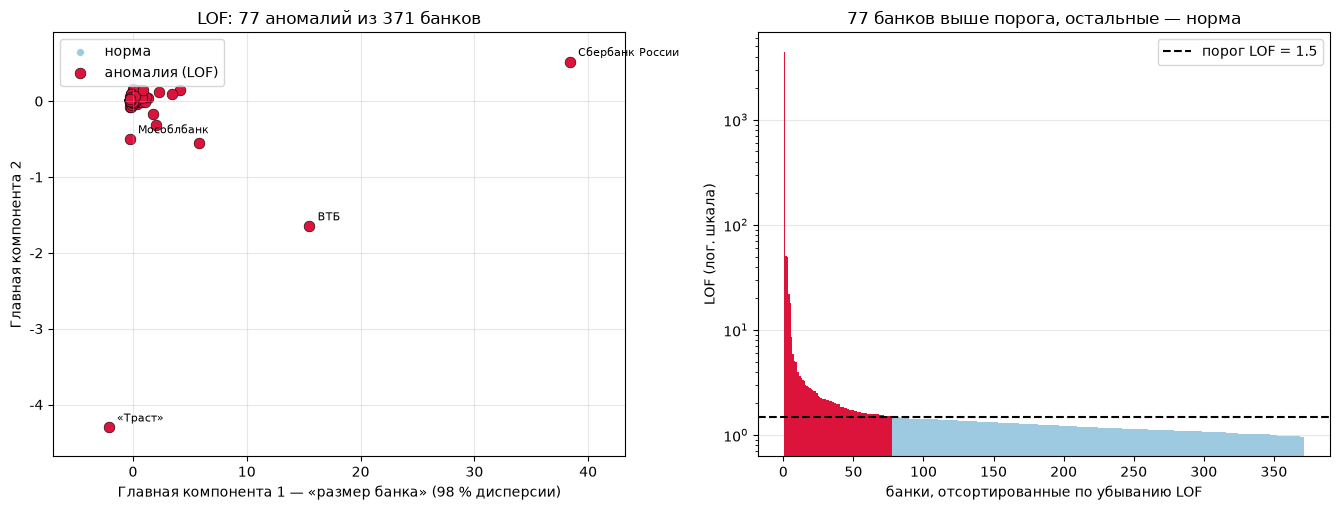

In [5]:
pcs = PCA(n_components=2).fit_transform(Z)
an_lof = labels_lof == -1

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))

ax = axes[0]
ax.scatter(pcs[~an_lof, 0], pcs[~an_lof, 1], s=30, color="#9ecae1",
           edgecolor="white", linewidth=0.3, label="норма")
ax.scatter(pcs[an_lof, 0], pcs[an_lof, 1], s=60, color="crimson",
           edgecolor="black", linewidth=0.4, label="аномалия (LOF)")

# подпишем несколько самых «сильных» аномалий
for idx in banks_lof.nlargest(4, "LOF").index:
    ax.annotate(banks_lof.loc[idx, "Bank"], (pcs[idx, 0], pcs[idx, 1]),
                textcoords="offset points", xytext=(6, 4), fontsize=8)

ax.set_xlabel("Главная компонента 1 — «размер банка» (98 % дисперсии)")
ax.set_ylabel("Главная компонента 2")
ax.set_title(f"LOF: {n_lof} аномалий из {len(banks)} банков")
ax.margins(x=0.12, y=0.08)
ax.legend(loc="upper left")
ax.grid(alpha=0.3)

ax = axes[1]
sorted_scores = np.sort(lof_score)[::-1]
bar_colors = np.where(sorted_scores > -lof_model.offset_, "crimson", "#9ecae1")
ax.bar(np.arange(1, len(sorted_scores) + 1), sorted_scores, color=bar_colors, width=1.0)
ax.axhline(-lof_model.offset_, color="black", linestyle="--",
           label=f"порог LOF = {-lof_model.offset_}")
ax.set_yscale("log")
ax.set_xlabel("банки, отсортированные по убыванию LOF")
ax.set_ylabel("LOF (лог. шкала)")
ax.set_title(f"{n_lof} банков выше порога, остальные — норма")
ax.legend()
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

**Комментарий к результату.** LOF пометил **77 банков из 371 (20,8 %)** — это много, но объяснимо:
порог 1,5 при `contamination='auto'` довольно мягкий, а распределение показателей имеет тяжёлый правый хвост.
В список попали:

* гиганты: Сбербанк (LOF = 50,1), ВТБ (21,8), Газпромбанк (8,6) — они далеко в правом хвосте;
* банки с **отрицательным собственным капиталом**: «Траст» (LOF = 4462 — абсолютный рекорд, капитал −1,36 млн),
  Мособлбанк (49,1), Балтинвестбанк (18,1) и др. — все 9 банков с отрицательным капиталом в списке;
* банки с «ломаными» пропорциями: нулевые средства физлиц при крупных активах («Кредит Свисс», «БМ-банк», «НФК»).

### Замечание о масштабировании (чувствительность результата)

LOF основан на расстояниях, поэтому результат зависит от того, как приведены признаки.
Проверим три варианта подготовки на одних и тех же параметрах алгоритма.

In [6]:
X_arr = X_banks.to_numpy()
X_signed_log = np.sign(X_arr) * np.log1p(np.abs(X_arr))     # логарифм сохраняет знак отрицательных значений

variants = {
    "сырые значения (без преобразования)": X_arr,
    "StandardScaler": Z,
    "log(|x|+1) + StandardScaler": StandardScaler().fit_transform(X_signed_log),
}

rows = []
for name, matrix in variants.items():
    labels_v = LocalOutlierFactor().fit_predict(matrix)
    rows.append({"вариант подготовки": name,
                 "аномалий": int((labels_v == -1).sum()),
                 "доля": round(float((labels_v == -1).mean()), 3)})
display(pd.DataFrame(rows))

,вариант подготовки,аномалий,доля
0,сырые значения (без преобразования),56,0.151
1,StandardScaler,77,0.208
2,log(|x|+1) + StandardScaler,47,0.127


Получается 56 → 77 → 47 аномалий в зависимости только от преобразования признаков.
В основной части работы используем **StandardScaler** (стандартная практика и требование «настройки по умолчанию»
относится к параметрам LOF, а не к подготовке данных), а логарифмический вариант оставляем как альтернативу:
он даёт более «содержательный» список (в нём нет Сбербанка, но есть банки с нулевыми показателями).
Главный вывод: **выбор подготовки данных влияет на результат сильнее, чем настройки алгоритма**.

## п.2. Сколько аномалий найдено

In [7]:
print(f"Всего банков:                        {len(banks)}")
print(f"Аномалий (label = -1):               {n_lof}")
print(f"Доля аномалий:                       {n_lof / len(banks):.1%}")
print(f"Порог: LOF > {-lof_model.offset_:.1f}")

print(f"\nСколько аномалий при более строгих порогах:")
for t in (1.5, 2, 3, 5, 10):
    print(f"  LOF > {t:>4}: {int((lof_score > t).sum()):>3} банков")

print(f"\nБанков с отрицательным капиталом:    {int((banks['OwnCapital'] < 0).sum())}")
print(f"  из них в списке аномалий:          {int((banks.loc[an_lof, 'OwnCapital'] < 0).sum())}")
print(f"Топ-10 банков по активам в аномалиях: {int(an_lof[banks['Assents'].nlargest(10).index].sum())} из 10")

print("\nПолный список найденных аномалий (отсортирован по LOF):")
display(banks_lof[an_lof][["Bank"] + FEATURES + ["LOF"]]
        .sort_values("LOF", ascending=False).reset_index(drop=True))

Всего банков:                        371
Аномалий (label = -1):               77
Доля аномалий:                       20.8%
Порог: LOF > 1.5

Сколько аномалий при более строгих порогах:
  LOF >  1.5:  77 банков
  LOF >    2:  36 банков
  LOF >    3:  16 банков
  LOF >    5:   8 банков
  LOF >   10:   5 банков

Банков с отрицательным капиталом:    9
  из них в списке аномалий:          9
Топ-10 банков по активам в аномалиях: 10 из 10

Полный список найденных аномалий (отсортирован по LOF):


,Bank,Assents,OwnCapital,IndFunds,NBSLoans,IndLoans,LOF
0,«Траст»,473754,-1357080,163,314021,7018,4462.044
1,Сбербанк России,32421026,4873465,14572552,21765857,8044812,50.111
2,Мособлбанк,433292,-133031,72027,88607,6039,49.132
3,ВТБ,15813216,1662670,4661791,10632646,3293583,21.771
4,Балтинвестбанк,46446,-20345,3992,30088,17998,18.122
...,...,...,...,...,...,...,...
72,Гута-банк,6134,3142,1026,654,408,1.518
73,Зираат-банк,8961,3161,1058,4326,51,1.517
74,Алтайкапиталбанк,3865,647,1445,2741,234,1.510
75,Собинбанк,6562,3045,271,123,0,1.510


**Итог п.2: 77 аномалий (20,8 %).**

Такой высокий процент — важный практический момент: `contamination='auto'` не означает «1 % аномалий»,
это конкретный порог 1,5. Больше половины списка (41 из 77) — банки с LOF от 1,5 до 2,0, т.е. «слегка непохожие».
Если нужен короткий список для проверки, разумно смотреть на LOF > 2 (36 банков) или LOF > 5 (8 банков):
это уже действительно экстремальные случаи.

## п.3. Отбрасываем аномалии и решаем задачу в режиме новизны (`novelty=True`)

**Что меняется в режиме новизны.** При `novelty=False` метод `fit_predict` размечает обучающую выборку
и не умеет обрабатывать новые объекты. При `novelty=True`:

* модель обучается **только на «нормальных» данных**, запоминает их структуру и внутренний порог;
* для новых объектов используется `predict` / `decision_function` — «насколько объект не похож на обучающую выборку»;
* `fit_predict` в этом режиме недоступен — сначала `fit`, потом `predict`.

Поэтому: убираем 77 найденных аномалий → на оставшихся 294 банках обучаем LOF с `novelty=True`
(параметры те же, по умолчанию) → получаем модель «эталонной нормы».

**Важная деталь:** масштабирование переобучаем **на очищенных данных**, иначе в среднее и отклонение
попали бы те самые выбросы, которые мы убрали (утечка информации).

In [8]:
clean = banks.loc[~an_lof].reset_index(drop=True)          # 294 «нормальных» банка
anomalies = banks.loc[an_lof].reset_index(drop=True)        # 77 ранее найденных аномалий

print(f"Очищенная выборка: {len(clean)} банков")
print(f"Отфильтрованные аномалии: {len(anomalies)} банков")

scaler_clean = StandardScaler().fit(clean[FEATURES])
Z_clean = scaler_clean.transform(clean[FEATURES])
Z_anom = scaler_clean.transform(anomalies[FEATURES])

lof_novelty = LocalOutlierFactor(novelty=True)      # те же настройки по умолчанию, но режим новизны
lof_novelty.fit(Z_clean)

pred_clean = lof_novelty.predict(Z_clean)
pred_anom = lof_novelty.predict(Z_anom)

print(f"\nМодель обучена на {len(clean)} банках, offset_ = {lof_novelty.offset_} "
      f"-> аномалия при LOF > {-lof_novelty.offset_}")
print(f"Внутри обучающей выборки модель считает аномалиями: {int((pred_clean == -1).sum())} "
      f"({(pred_clean == -1).mean():.1%})")

Очищенная выборка: 294 банков
Отфильтрованные аномалии: 77 банков

Модель обучена на 294 банках, offset_ = -1.5 -> аномалия при LOF > 1.5
Внутри обучающей выборки модель считает аномалиями: 21 (7.1%)


Интересный побочный результат: даже в «очищенных» данных модель новизны находит 21 банк,
который выходит за порог. Это **вторая волна** аномалий — банки, которые были не так экстремальны,
как убранные 77, но всё же выделяются на фоне оставшихся. В их числе «Ак Барс», «Русский стандарт», ДОМ.РФ,
СМП — те самые четыре банка, которые позже найдёт Isolation Forest, но не нашёл LOF (см. п. 5).

## п.4. Прогоняем ранее отфильтрованные аномалии через модель из п.3

Подаём 77 «старых» аномалий в модель новизны и считаем, сколько из них она снова признает аномалиями —
это и есть число совпадений.

In [9]:
matched = int((pred_anom == -1).sum())

print(f"Подано на вход ранее найденных аномалий: {len(anomalies)}")
print(f"Модель новизны снова признала аномалиями: {matched}")
print(f"Число совпадений:                        {matched} из {len(anomalies)}  ({matched / len(anomalies):.1%})")
print(f"Не признаны аномалиями:                  {len(anomalies) - matched}")

result = banks_lof.loc[an_lof, ["Bank"] + FEATURES + ["LOF"]].reset_index(drop=True)
result["decision"] = np.round(lof_novelty.decision_function(Z_anom), 3)
result["predicted"] = pred_anom

print("\nСамые «уверенные» совпадения (минимальное decision_function = максимальная аномальность):")
display(result.sort_values("decision").head(10).reset_index(drop=True))

print("\nАномалии, которые модель новизны НЕ подтвердила:")
display(result[result["predicted"] == 1].reset_index(drop=True))

Подано на вход ранее найденных аномалий: 77
Модель новизны снова признала аномалиями: 76
Число совпадений:                        76 из 77  (98.7%)
Не признаны аномалиями:                  1

Самые «уверенные» совпадения (минимальное decision_function = максимальная аномальность):


,Bank,Assents,OwnCapital,IndFunds,NBSLoans,IndLoans,LOF,decision,predicted
0,«Траст»,473754,-1357080,163,314021,7018,4462.044,-7312.261,-1
1,Сбербанк России,32421026,4873465,14572552,21765857,8044812,50.111,-296.651,-1
2,ВТБ,15813216,1662670,4661791,10632646,3293583,21.771,-124.038,-1
3,Мособлбанк,433292,-133031,72027,88607,6039,49.132,-70.784,-1
4,Газпромбанк,7613174,746441,1408510,4767259,690853,8.582,-49.744,-1
5,Альфа-банк,4229025,612922,1350517,2662749,811424,5.882,-31.401,-1
6,Россельхозбанк,3539546,507453,1265917,2458609,509208,5.026,-26.572,-1
7,Московский кредитный банк,2988171,271793,493696,2199626,130331,3.950,-19.683,-1
8,«ФК Открытие»,2530760,358641,938382,1468180,423075,3.665,-17.027,-1
9,Балтинвестбанк,46446,-20345,3992,30088,17998,18.122,-15.993,-1



Аномалии, которые модель новизны НЕ подтвердила:


,Bank,Assents,OwnCapital,IndFunds,NBSLoans,IndLoans,LOF,decision,predicted
0,Камский коммерческий банк,3806,558,2329,2249,1517,1.591,0.114,1


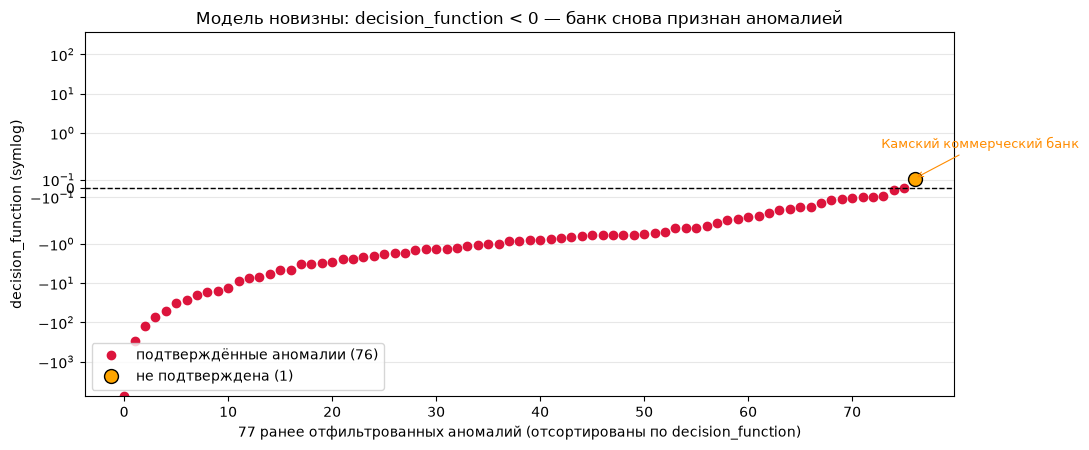

In [10]:
order = np.argsort(result["decision"].to_numpy())
plot_data = result.iloc[order].reset_index(drop=True)
is_missed = plot_data["predicted"].to_numpy() == 1

fig, ax = plt.subplots(figsize=(11, 4.6))
ax.plot(np.arange(len(plot_data))[~is_missed], plot_data.loc[~is_missed, "decision"],
        "o", ms=6, color="crimson", label=f"подтверждённые аномалии ({int((~is_missed).sum())})")
ax.plot(np.arange(len(plot_data))[is_missed], plot_data.loc[is_missed, "decision"],
        "o", ms=10, color="orange", markeredgecolor="black", label=f"не подтверждена ({int(is_missed.sum())})")
ax.axhline(0, color="black", linewidth=1, linestyle="--")
ax.set_yscale("symlog", linthresh=0.5)
ax.set_xlabel("77 ранее отфильтрованных аномалий (отсортированы по decision_function)")
ax.set_ylabel("decision_function (symlog)")
ax.set_title("Модель новизны: decision_function < 0 — банк снова признан аномалией")

pos = int(np.flatnonzero(is_missed)[0])
ax.annotate(plot_data.loc[pos, "Bank"], (pos, plot_data.loc[pos, "decision"]),
            textcoords="offset points", xytext=(-24, 22), fontsize=9, color="darkorange",
            arrowprops=dict(arrowstyle="->", color="darkorange", linewidth=0.8))

ax.legend(loc="lower left")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

**Итог п.4: совпало 76 из 77 аномалий — 98,7 %.**

Не подтвердился один банк — «Камский коммерческий банк»: в исходной модели его LOF был 1,591, т.е. чуть выше порога.
После того как из данных убрали 77 самых экстремальных банков, его окружение изменилось (многие его соседи
были такими же «пограничными» аномалиями и тоже удалены), локальная плотность вокруг него выросла,
и значение LOF опустилось ниже 1,5. Это нормальное поведение метода: **граница между нормой и аномалией
зависит от состава выборки**, поэтому «пограничные» объекты нестабильны.

Практический вывод: обучение на очищенных данных воспроизводит список аномалий почти полностью,
но для объектов у самого порога решение может измениться.

## п.5. Isolation Forest

**Идея.** Строятся случайные деревья: на каждом шаге выбирается случайный признак и случайный порог,
пока точка не изолируется в отдельный лист. Аномалию изолировать **легче** — путь до неё короче:

$$s(x, n) = 2^{-\frac{E[h(x)]}{c(n)}}$$

где $h(x)$ — длина пути до листа, $c(n)$ — нормировка на среднюю длину пути. Чем ближе $s$ к 1, тем более
точка аномальна. Параметры по умолчанию: `n_estimators=100`, `max_samples='auto'`, `contamination='auto'`
(порог `offset_ = -0.5`).

In [11]:
iso_model = IsolationForest(random_state=42)
labels_if = iso_model.fit_predict(Z)
if_score = -iso_model.score_samples(Z)

n_if = int((labels_if == -1).sum())
print(f"Параметры: n_estimators={iso_model.n_estimators}, max_samples={iso_model.max_samples}, "
      f"contamination={iso_model.contamination}")
print(f"offset_ = {iso_model.offset_}")
print(f"\nНайдено аномалий: {n_if} из {len(banks)}  ({n_if / len(banks):.1%})")

banks_if = banks.assign(IF=if_score.round(4)).sort_values("IF", ascending=False)
print("\nТоп-10 аномалий по Isolation Forest:")
display(banks_if[["Bank"] + FEATURES + ["IF"]].head(10).reset_index(drop=True))

an_if = labels_if == -1
print("\nСравнение с LOF (настройки по умолчанию у обоих):")
display(pd.crosstab(pd.Series(labels_lof, name="LOF"), pd.Series(labels_if, name="Isolation Forest")))
print(f"Пересечение: {int((an_lof & an_if).sum())} банков;  "
      f"Jaccard = {jaccard_score(an_lof.astype(int), an_if.astype(int)):.3f}")
print("Аномалии Isolation Forest, которых нет у LOF:",
      banks.loc[an_if & ~an_lof, "Bank"].tolist())

Параметры: n_estimators=100, max_samples=auto, contamination=auto
offset_ = -0.5

Найдено аномалий: 30 из 371  (8.1%)

Топ-10 аномалий по Isolation Forest:


,Bank,Assents,OwnCapital,IndFunds,NBSLoans,IndLoans,IF
0,Сбербанк России,32421026,4873465,14572552,21765857,8044812,0.8992
1,ВТБ,15813216,1662670,4661791,10632646,3293583,0.8559
2,Газпромбанк,7613174,746441,1408510,4767259,690853,0.7754
3,Альфа-банк,4229025,612922,1350517,2662749,811424,0.7440
4,Россельхозбанк,3539546,507453,1265917,2458609,509208,0.7261
5,Московский кредитный банк,2988171,271793,493696,2199626,130331,0.7039
6,«ФК Открытие»,2530760,358641,938382,1468180,423075,0.6986
7,Промсвязьбанк,2503499,242334,503089,1401834,318334,0.6649
8,«Траст»,473754,-1357080,163,314021,7018,0.6500
9,Райффайзенбанк,1432353,200008,579245,820678,315993,0.6395



Сравнение с LOF (настройки по умолчанию у обоих):


Isolation Forest,-1,1
LOF,,
-1,26,51
1,4,290


Пересечение: 26 банков;  Jaccard = 0.321
Аномалии Isolation Forest, которых нет у LOF: ['«Ак Барс»', '«Русский стандарт»', 'ДОМ.РФ', 'СМП']


,метод,аномалий,доля,совпало с LOF
0,"LOF (default, novelty=False)",77,0.208,77
1,Isolation Forest (default),30,0.081,26
2,Isolation Forest (contamination = доля LOF),77,0.208,41


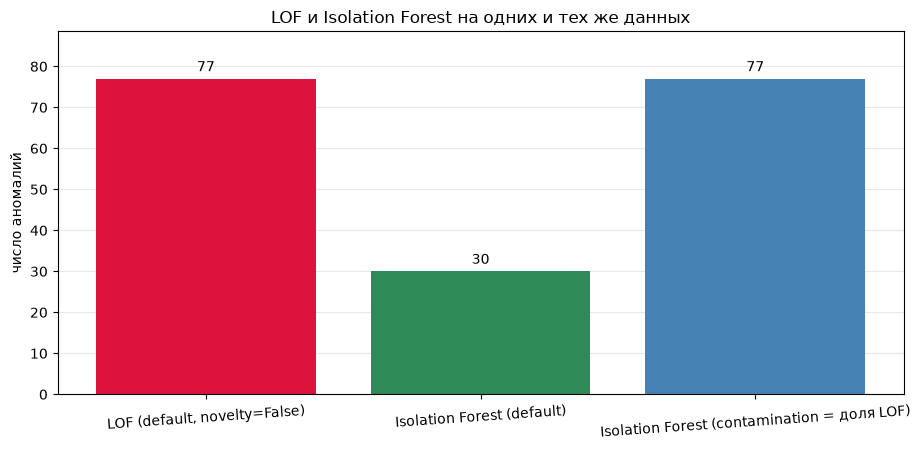

In [12]:
# Чтобы сравнение было честным, зададим Isolation Forest ту же долю аномалий, что нашёл LOF
iso_same = IsolationForest(contamination=n_lof / len(banks), random_state=42)
labels_if_same = iso_same.fit_predict(Z)
an_if_same = labels_if_same == -1

compare = pd.DataFrame([
    {"метод": "LOF (default, novelty=False)", "аномалий": n_lof,
     "доля": round(n_lof / len(banks), 3), "совпало с LOF": n_lof},
    {"метод": "Isolation Forest (default)", "аномалий": n_if,
     "доля": round(n_if / len(banks), 3), "совпало с LOF": int((an_if & an_lof).sum())},
    {"метод": "Isolation Forest (contamination = доля LOF)", "аномалий": int(an_if_same.sum()),
     "доля": round(float(an_if_same.mean()), 3), "совпало с LOF": int((an_if_same & an_lof).sum())},
])
display(compare)

fig, ax = plt.subplots(figsize=(9.5, 4.6))
bars = ax.bar(compare["метод"], compare["аномалий"], color=["crimson", "seagreen", "steelblue"])
ax.bar_label(bars, padding=3)
ax.set_ylabel("число аномалий")
ax.set_title("LOF и Isolation Forest на одних и тех же данных")
ax.set_ylim(0, max(compare["аномалий"]) * 1.15)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
plt.xticks(rotation=4)
plt.tight_layout()
plt.show()

**Итог п.5.** При настройках по умолчанию Isolation Forest находит **30 аномалий (8,1 %)**,
из которых 26 (87 %) входят и в список LOF. Четыре «своих» банка —
«Ак Барс», «Русский стандарт», ДОМ.РФ, СМП — это крупные банки с нетипичными пропорциями;
LOF их не видит, потому что рядом с ними есть похожие соседи, а для случайных разрезов они всё равно «далеко».

Если задать Isolation Forest ту же долю аномалий, что нашёл LOF (77 банков), совпадение составит **41 из 77 (53 %)**.
Вывод: ядро аномалий (банки-гиганты и банки с отрицательным капиталом) методы находят одинаково,
а периферия зависит от определения аномальности.

## п.6. Метрики качества в задачах Anomaly Detection

### Почему здесь нельзя просто посчитать accuracy

В поиске аномалий **нет эталонной разметки** (мы как раз её и ищем), а классы сильно несбалансированы.
Если аномалий 1 % и модель объявит «всё нормально», accuracy будет 99 %, хотя модель бесполезна.
Поэтому метрики делят на три группы.

### 6.1. Метрики, требующие эталонных меток

Обозначения: $TP$ — аномалия найдена, $FP$ — нормальный объект назван аномалией (ложная тревога),
$FN$ — аномалия пропущена, $TN$ — норма определена верно.

| Метрика | Формула | Смысл | Когда использовать |
|---|---|---|---|
| **Precision** (точность) | $TP/(TP+FP)$ | доля настоящих аномалий среди найденных | когда дорогая проверка каждого кандидата (сколько «пустых» проверок) |
| **Recall** (полнота, TPR) | $TP/(TP+FN)$ | доля найденных аномалий из всех существующих | когда пропуск аномалии дорог (мошенничество, сбой) |
| **F1** | $2 \cdot \frac{P \cdot R}{P + R}$ | среднее гармоническое точности и полноты | нужен один баланс P/R |
| **$F_\beta$** | $(1+\beta^2)\frac{P R}{\beta^2 P + R}$ | $\beta > 1$ — важнее полнота, $\beta < 1$ — точность | задан приоритет ошибок |
| **ROC-AUC** | площадь под кривой TPR–FPR | качество **ранжирования** по оценке, независимо от порога | сравнение моделей, разметка примерно сбалансирована |
| **PR-AUC / AP** | площадь под кривой Precision–Recall | то же, но устойчивее при **сильной несбалансированности** | стандарт для редких аномалий |
| **MCC** | учитывает все 4 клетки таблицы | качество при дисбалансе, «−1…+1» | один честный скаляр при перекосе классов |
| Accuracy | $(TP+TN)/n$ | — | **не использовать**: при 1 % аномалий даёт 0,99 «ничего не делая» |

### 6.2. Метрики, не требующие разметки

| Подход | Что показывает |
|---|---|
| **Согласие моделей**: Jaccard, Cohen's $\kappa$, Adjusted Rand Index | насколько совпадают списки LOF и Isolation Forest; $\kappa \approx 0$ — случайно, $> 0,6$ — сильное согласие |
| **Внутренние метрики**: silhouette, Davies–Bouldin, Calinski–Harabasz | насколько компактно разделились «норма» и «аномалии» в пространстве признаков (оценивает **геометрию**, а не правильность) |
| **Стабильность (bootstrap)** | как часто объект попадает в аномалии на подвыборках: устойчивые аномалии — приоритет для проверки |
| **precision@K по экспертной проверке** | из $K$ первых кандидатов сколько подтвердил аналитик — главная бизнес-метрика |
| **Пороговые метрики** | число аномалий при разных порогах: порог — это управляемый гиперпараметр, а не «истина» |

### 6.3. Демонстрация: синтетические данные с известной разметкой

Чтобы увидеть, как считаются метрики, сгенерируем данные, где правильный ответ известен:
облако нормальных точек и 30 аномалий на окружности.

In [13]:
rng = np.random.default_rng(0)
n_normal, n_anom = 600, 30

normal_pts = rng.normal(0, 1, size=(n_normal, 2))
anom_pts = rng.normal(size=(n_anom, 2))
anom_pts = anom_pts / np.linalg.norm(anom_pts, axis=1, keepdims=True) * 4.5

X_syn = np.vstack([normal_pts, anom_pts])
y_syn = np.r_[np.zeros(n_normal, dtype=int), np.ones(n_anom, dtype=int)]
cont_syn = y_syn.mean()

print(f"Точек: {len(X_syn)}, из них аномалий: {n_anom} ({cont_syn:.1%})")
print("Разметка известна, поэтому можно честно посчитать precision, recall, ROC-AUC и AP.\n")

lof_syn = LocalOutlierFactor(contamination=cont_syn)
y_lof_syn = (lof_syn.fit_predict(X_syn) == -1).astype(int)

iso_syn = IsolationForest(contamination=cont_syn, random_state=42)
y_if_syn = (iso_syn.fit_predict(X_syn) == -1).astype(int)

score_lof_syn = -lof_syn.negative_outlier_factor_
score_if_syn = -iso_syn.score_samples(X_syn)


def quality(y_true, y_pred, score):
    return {"Precision": precision_score(y_true, y_pred),
            "Recall": recall_score(y_true, y_pred),
            "F1": f1_score(y_true, y_pred),
            "MCC": matthews_corrcoef(y_true, y_pred),
            "ROC-AUC": roc_auc_score(y_true, score),
            "PR-AUC (AP)": average_precision_score(y_true, score)}


quality_table = pd.DataFrame({"LOF": quality(y_syn, y_lof_syn, score_lof_syn),
                              "Isolation Forest": quality(y_syn, y_if_syn, score_if_syn)}).T
display(quality_table.round(3))

Точек: 630, из них аномалий: 30 (4.8%)
Разметка известна, поэтому можно честно посчитать precision, recall, ROC-AUC и AP.



,Precision,Recall,F1,MCC,ROC-AUC,PR-AUC (AP)
LOF,0.933,0.933,0.933,0.930,0.998,0.938
Isolation Forest,0.967,0.967,0.967,0.965,0.999,0.974


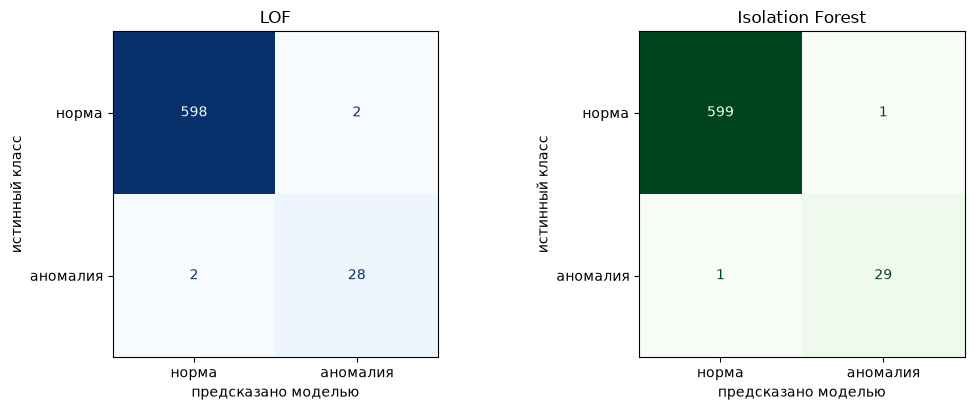

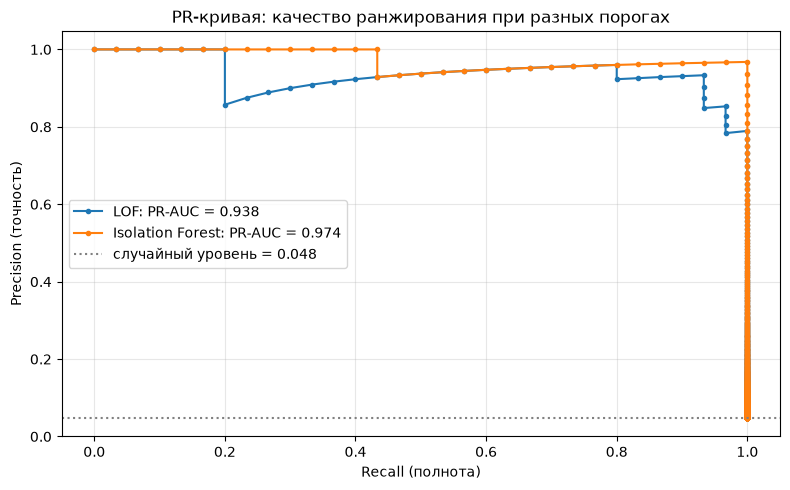

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, y_pred, title, cmap in [(axes[0], y_lof_syn, "LOF", "Blues"),
                                (axes[1], y_if_syn, "Isolation Forest", "Greens")]:
    ConfusionMatrixDisplay.from_predictions(y_syn, y_pred, labels=[0, 1],
                                            display_labels=["норма", "аномалия"],
                                            cmap=cmap, colorbar=False, ax=ax)
    ax.set_xlabel("предсказано моделью")
    ax.set_ylabel("истинный класс")
    ax.set_title(title)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
for name, score in [("LOF", score_lof_syn), ("Isolation Forest", score_if_syn)]:
    precision_curve, recall_curve, _ = precision_recall_curve(y_syn, score)
    ap = average_precision_score(y_syn, score)
    ax.plot(recall_curve, precision_curve, marker=".", label=f"{name}: PR-AUC = {ap:.3f}")
ax.axhline(cont_syn, color="gray", linestyle=":", label=f"случайный уровень = {cont_syn:.3f}")
ax.set_xlabel("Recall (полнота)")
ax.set_ylabel("Precision (точность)")
ax.set_title("PR-кривая: качество ранжирования при разных порогах")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Что показала демонстрация:**

* при известной доле аномалий оба метода дают высокие Precision/Recall (≈ 0,93–0,97) и почти идеальный ROC-AUC;
* **PR-AUC** (≈ 0,94–0,97) — здесь более информативная метрика, чем ROC-AUC, потому что аномалий всего 4,8 %;
* матрица ошибок сразу показывает цену решения: сколько нормальных объектов мы отправим «на проверку» (FP)
  и сколько аномалий пропустим (FN);
* PR-кривая позволяет выбрать порог: смещая его, мы обмениваем полноту на точность.

### 6.4. Применяем метрики к нашим данным (без разметки)

Разметки для `banks.txt` нет, поэтому «эталоном» может быть только другой метод или эксперт.
Посчитаем согласие методов и устойчивость списка.

In [15]:
y_lof_b = an_lof.astype(int)
y_if_b = an_if.astype(int)

print("Согласие методов (LOF vs Isolation Forest, настройки по умолчанию):")
print(f"  Jaccard:            {jaccard_score(y_lof_b, y_if_b):.3f}")
print(f"  Cohen's kappa:      {cohen_kappa_score(y_lof_b, y_if_b):.3f}")
print(f"  Adjusted Rand:      {adjusted_rand_score(y_lof_b, y_if_b):.3f}")

print("\nВнутренние метрики (silhouette — насколько группы разделимы в пространстве):")
print(f"  по меткам LOF:              {silhouette_score(Z, y_lof_b):.3f}")
print(f"  по меткам Isolation Forest: {silhouette_score(Z, y_if_b):.3f}")

print("\nprecision@K — считая список Isolation Forest «эталоном»:")
order = np.argsort(-lof_score)
for k in (10, 20, 30, 50):
    print(f"  precision@{k:<3} = {y_if_b[order[:k]].mean():.2f}")

Согласие методов (LOF vs Isolation Forest, настройки по умолчанию):
  Jaccard:            0.321
  Cohen's kappa:      0.418
  Adjusted Rand:      0.335

Внутренние метрики (silhouette — насколько группы разделимы в пространстве):
  по меткам LOF:              0.602
  по меткам Isolation Forest: 0.856

precision@K — считая список Isolation Forest «эталоном»:
  precision@10  = 0.70
  precision@20  = 0.75
  precision@30  = 0.60
  precision@50  = 0.46


In [16]:
# Устойчивость: 100 раз обучаем LOF на случайной подвыборке 80 % банков
rng_boot = np.random.default_rng(1)
n_boot = 100
hits = np.zeros(len(banks))

for _ in range(n_boot):
    idx = rng_boot.choice(len(banks), size=int(0.8 * len(banks)), replace=False)
    labels_boot = LocalOutlierFactor().fit_predict(Z[idx])
    hits[idx[labels_boot == -1]] += 1

stability = pd.Series(hits / n_boot, index=banks["Bank"], name="устойчивость")

print("Самые устойчивые аномалии (доля подвыборок, где банк признан аномалией):")
display(stability.sort_values(ascending=False).head(12).round(2).to_frame())
print(f"Банков с устойчивостью ≥ 0,5: {(stability >= 0.5).sum()}")
print(f"Банков с устойчивостью = 1,0: {(stability == 1).sum()}")

Самые устойчивые аномалии (доля подвыборок, где банк признан аномалией):


,устойчивость
Bank,
Генбанк,0.88
Ффин-банк,0.87
Юникредит-банк,0.87
Инвестторгбанк,0.85
Севастопольский морской банк,0.85
«Ренессанс Кредит»,0.84
Райффайзенбанк,0.84
ВБРР,0.84
МС Банк Рус,0.84


Банков с устойчивостью ≥ 0,5: 99
Банков с устойчивостью = 1,0: 0


**Интерпретация для наших данных.**

* Jaccard ≈ 0,32 и Cohen's $\kappa$ ≈ 0,42 — согласие **умеренное**: методы находят общее ядро
  (крупнейшие банки и банки с отрицательным капиталом), но расходятся на периферии. Это ожидаемо,
  ведь LOF ищет локальную плотность, а Isolation Forest — глобальную изолируемость.
* Silhouette 0,60 (LOF) и 0,86 (Isolation Forest) говорит лишь о том, что группы хорошо разделимы
  геометрически, — это **не** доказательство правильности: IF просто отрезает край распределения.
* precision@20 ≈ 0,75 означает: если проверять первые 20 банков по LOF, три четверти из них
  Isolation Forest тоже считает аномальными. Это не «истина», но разумный способ приоритизировать проверку.
* Устойчивость показывает главное: список LOF (а это 20 % всех банков) очень чувствителен к составу выборки,
  максимальная устойчивость — около 0,88. Для отчёта надёжнее брать объекты с высокой устойчивостью
  и высоким LOF (LOF > 5 — это всего 8 банков).

**Главный вывод по метрикам:** без разметки нельзя получить настоящие Precision/Recall. Работают:
согласие между методами, устойчивость к подвыборкам, precision@K после проверки экспертом и контроль доли
отсекаемых объектов (порог). А ROC-AUC / PR-AUC / F1 / MCC применяют, когда появилась хотя бы частичная
разметка (например, подтверждённые аналитиком случаи).

## Общие выводы по работе

| Пункт | Что сделано | Результат |
|---|---|---|
| 1 | LOF, `novelty=False`, настройки по умолчанию (`n_neighbors=20`, `contamination='auto'`) | 77 аномалий |
| 2 | Число аномалий | **77 из 371 (20,8 %)**; при LOF > 2 — 36, при LOF > 5 — 8 |
| 3 | Аномалии отфильтрованы, LOF(`novelty=True`) обучен на 294 «нормальных» банках | модель «эталонной нормы»; 21 банк «второй волны» |
| 4 | Прогон 77 отфильтрованных аномалий через модель п.3 | **76 из 77 (98,7 %)** совпадений; не подтвердился «Камский коммерческий банк» (LOF 1,591) |
| 5 | Isolation Forest (`n_estimators=100`, `contamination='auto'`) | **30 аномалий (8,1 %)**, 26 совпали с LOF; при одинаковой доле — 77 аномалий, 41 совпадение |
| 6 | Метрики Anomaly Detection | изучены Precision, Recall, F1, ROC-AUC, PR-AUC/AP, MCC, согласие методов, silhouette, устойчивость; продемонстрированы на синтетике с разметкой и на реальных данных |

**Содержательная картина аномалий в banks.txt.** Аномальными оказываются:

1. **гиганты** (Сбербанк, ВТБ, Газпромбанк, Россельхозбанк, Альфа-банк) — они далеко в правом хвосте распределения;
2. **банки с отрицательным капиталом** («Траст» — LOF 4462, Мособлбанк, Балтинвестбанк, ВУЗ-банк, Генбанк и др.) — все 9 попали в список;
3. **банки с «ломаными» пропорциями**: нулевые средства физлиц или нулевые кредиты при заметных активах
   («Кредит Свисс», «БМ-банк», «НФК», «Ю БИ ЭС Банк»).

**Методические выводы:**

* Режим `novelty=True` не «перепроверяет» старый список, а строит модель нормы заново: 98,7 % аномалий
  подтверждаются, но объекты у самого порога (LOF ≈ 1,5) могут «погаснуть» — граница зависит от выборки.
* Количество аномалий при `contamination='auto'` — не 1 % и не 5 %, а следствие конкретного порога
  (LOF > 1,5 и score < −0,5). Порог нужно выбирать под задачу: LOF > 5 даёт короткий список из 8 банков
  для ручной проверки.
* Подготовка данных (масштабирование, логарифмирование) меняет результат сильнее, чем смена алгоритма: 56 / 77 / 47 аномалий.
* Без разметки качество оценивают согласием методов, устойчивостью к подвыборкам и precision@K после
  экспертной проверки; метрики Precision/Recall/F1/ROC-AUC/AP/MCC применимы, когда разметка появилась.